In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns


In [4]:
df = pd.concat([
    pd.read_csv('results_20261022_152025/all_results.csv'),
    pd.read_csv('results_20261025_183402/all_results.csv'),
    pd.read_csv('results_20261025_162053/all_results.csv')
], ignore_index=True)

df.head()

,feature,window,embedding,classifier,accuracy,time,params,error
0,event_type,7,pca,logreg,0.583333,5.483837,"{'C': 0.014914672053545254, 'fit_intercept': T...",NaN
1,event_type,7,pca,dt,0.601852,0.575785,"{'max_depth': 6, 'criterion': 'entropy'}",NaN
2,event_type,7,pca,rf,0.611111,8.839631,"{'n_estimators': 63, 'max_depth': 14}",NaN
3,event_type,7,pca,knn,0.601852,0.366695,"{'n_neighbors': 18, 'weights': 'uniform', 'alg...",NaN
4,event_type,7,pca,xgboost,0.537037,6.147301,"{'n_estimators': 23, 'learning_rate': 0.240147...",NaN


In [6]:
df[df['feature'] == 'Continent'].sort_values('accuracy', ascending=False).head(5)

,feature,window,embedding,classifier,accuracy,time,params,error
321,Continent,30,pca,dt,0.490385,0.563033,"{'max_depth': 8, 'criterion': 'gini'}",NaN
369,Continent,30,nnclr_cnn,dt,0.480769,2.431037,"{'max_depth': 4, 'criterion': 'log_loss'}",NaN
348,Continent,30,fft,xgboost,0.480769,46.246719,"{'n_estimators': 156, 'learning_rate': 0.02473...",NaN
338,Continent,30,wavelet,rf,0.480769,20.495670,"{'n_estimators': 184, 'max_depth': 15}",NaN
346,Continent,30,fft,rf,0.471154,30.151894,"{'n_estimators': 170, 'max_depth': 11}",NaN


In [5]:
df_event = df[df['feature'] == 'event_type']
df_continent = df[df['feature'] == 'Continent']
print('Best accuracy when classified per event type:')
for i,row in df_event[df_event['accuracy'] == df_event['accuracy'].max()].iterrows():
    print(f'window = {row['window']} days, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
    
print('\n Worst accuracy when classified per event type:')
for i,row in df_event[df_event['accuracy'] == df_event['accuracy'].min()].iterrows():
    print(f'window = {row['window']} days, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
    

print('\nBest accuracy when classified per continent:')
for i,row in df_continent[df_continent['accuracy'] == df_continent['accuracy'].max()].iterrows():
    print(f'window = {row['window']} days, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
    
print('\nWorst accuracy when classified per continent:')
for i,row in df_continent[df_continent['accuracy'] == df_continent['accuracy'].min()].iterrows():
    print(f'window = {row['window']} days, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
    

Best accuracy when classified per event type:
window = 30 days, embedding method = MantisV2, classifier = svm, accuracy = 0.781

 Worst accuracy when classified per event type:
window = 7 days, embedding method = lle, classifier = nb, accuracy = 0.343

Best accuracy when classified per continent:
window = 30 days, embedding method = MantisV2, classifier = svm, accuracy = 0.55

Worst accuracy when classified per continent:
window = 7 days, embedding method = nnclr_lstm, classifier = nb, accuracy = 0.154


In [7]:
for window in [7,14,30]:
    df_window = df[df['window'] == window]
    
    
    print(f'\nBest accuracy when classified using a {window} days window:')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].max()].iterrows():
        print(f'feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    print(f'\nWorst accuracy when classified using a {window} days window')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].min()].iterrows():
        print(f'feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    


Best accuracy when classified using a 7 days window:
feature = event_type, embedding method = MantisPlus, classifier = xgboost, accuracy = 0.742

Worst accuracy when classified using a 7 days window
feature = Continent, embedding method = nnclr_lstm, classifier = nb, accuracy = 0.154

Best accuracy when classified using a 14 days window:
feature = event_type, embedding method = MantisPlus, classifier = knn, accuracy = 0.77

Worst accuracy when classified using a 14 days window
feature = Continent, embedding method = nnclr_lstm, classifier = nb, accuracy = 0.212

Best accuracy when classified using a 30 days window:
feature = event_type, embedding method = MantisV2, classifier = svm, accuracy = 0.781

Worst accuracy when classified using a 30 days window
feature = Continent, embedding method = nnclr_cnn, classifier = nb, accuracy = 0.212


Text(0.5, 0.98, 'Barplot of accuracy score per embedding method')

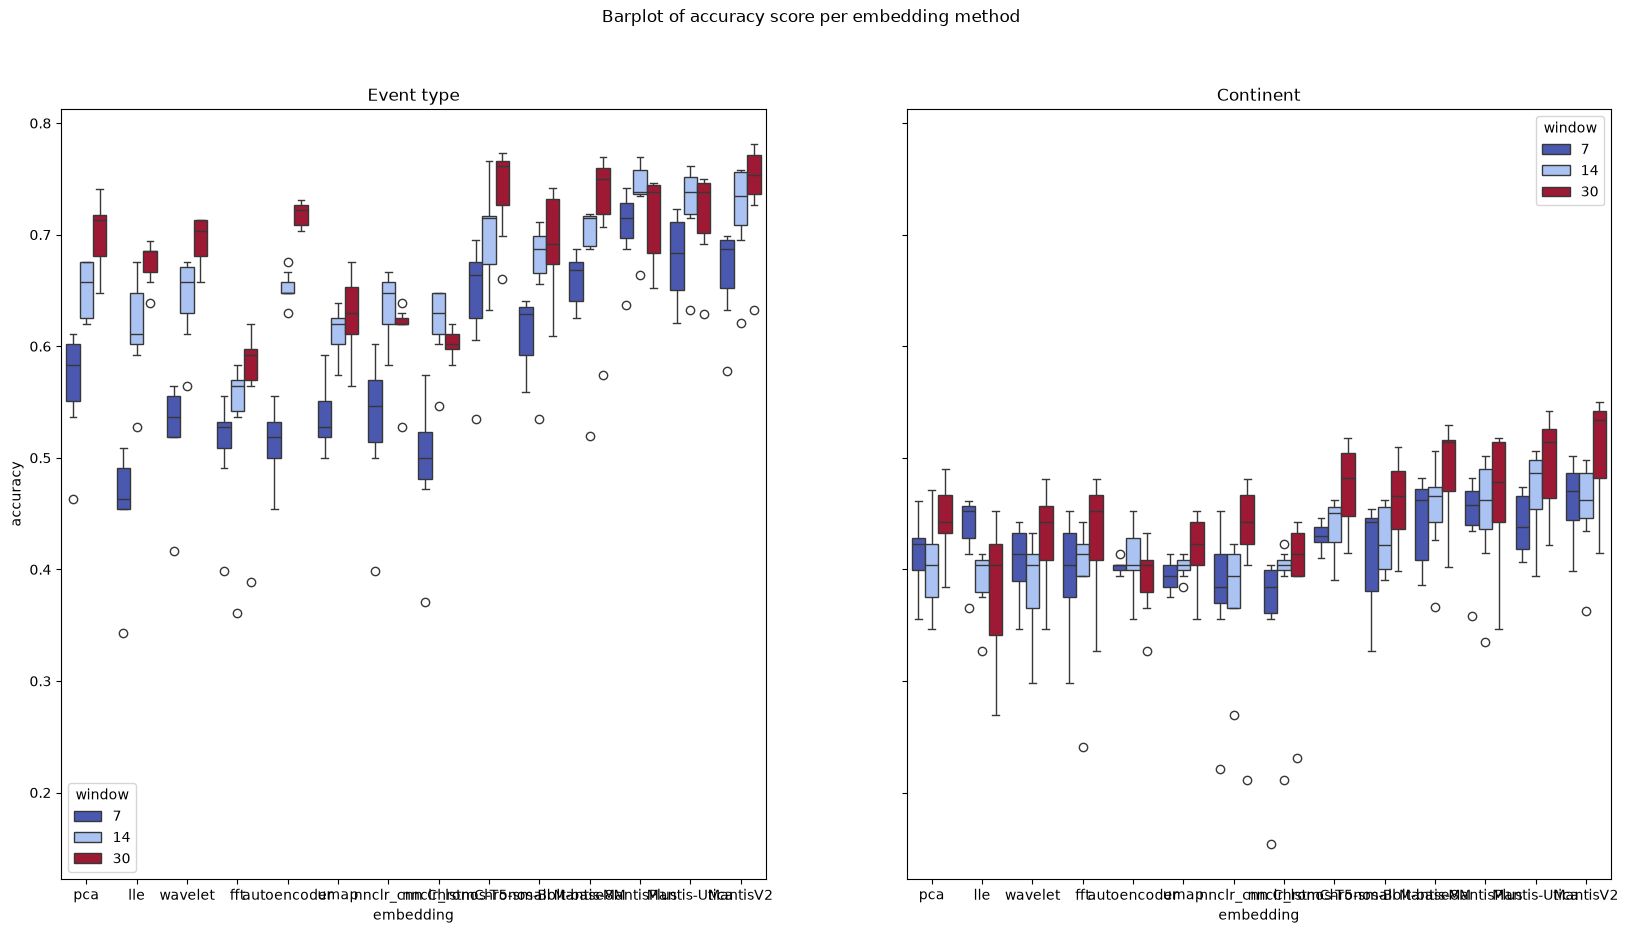

In [8]:
fig, axes = plt.subplots(
        nrows=1, 
        ncols=2, 
        figsize=(20, 10), sharey= True

    )

sns.boxplot(
    data=df[df['feature'] == 'event_type'],
    x='embedding',
    y='accuracy',
    hue='window',
    palette='coolwarm',
    ax=axes[0]
)
axes[0].set_title('Event type')
sns.boxplot(
    data=df[df['feature'] == 'Continent'],
    x='embedding',
    y='accuracy',
    hue='window',
    palette='coolwarm',
    ax=axes[1]
)
#axes[1].set_title('Barplot of accuracy score per embedding method for continent classification')
axes[1].set_title('Continent')
fig.suptitle('Barplot of accuracy score per embedding method')

<Axes: xlabel='embedding', ylabel='accuracy'>

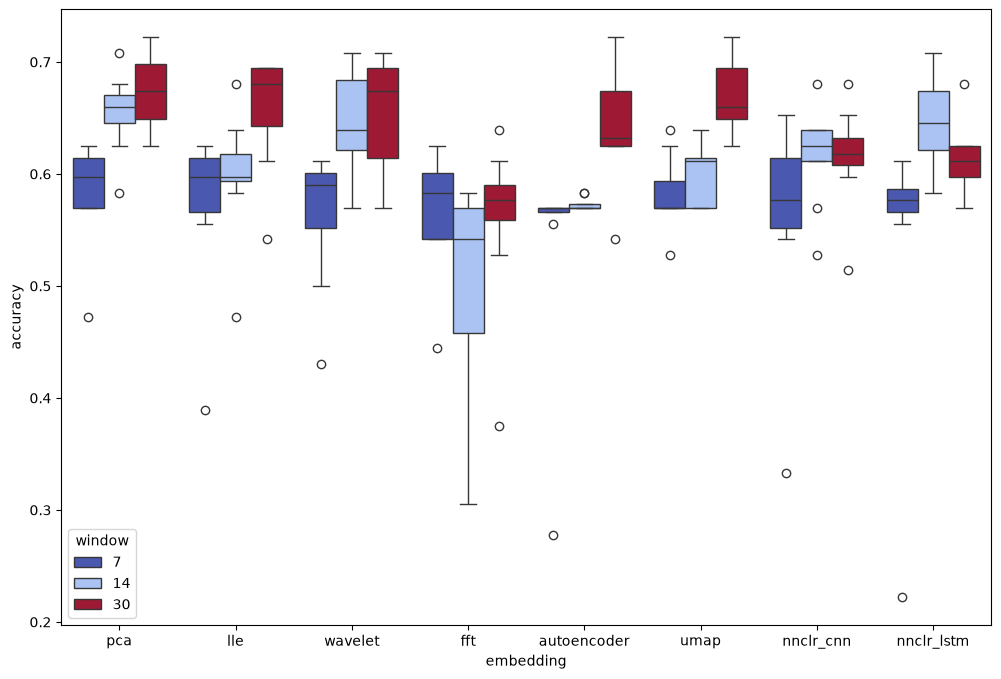

In [16]:
# 
plt.figure(figsize=(12, 8))
sns.boxplot(
    data=df[df['feature'] == 'event_type'],
    x='embedding',
    y='accuracy',
    hue='window',
    palette='coolwarm'
)

<Axes: xlabel='embedding', ylabel='accuracy'>

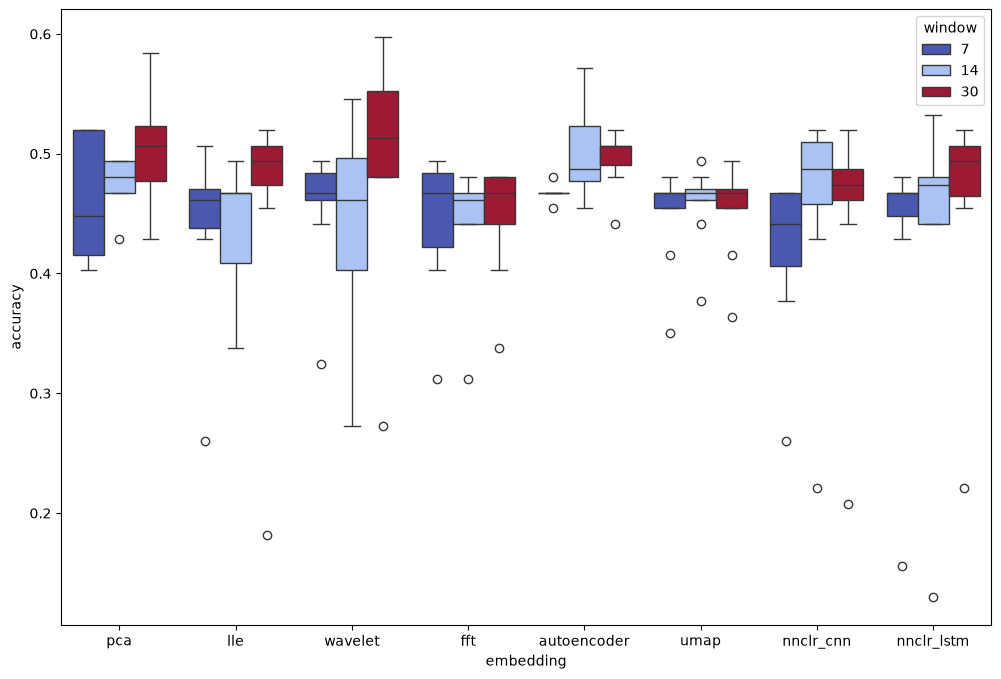

In [17]:
# 
plt.figure(figsize=(12, 8))
sns.boxplot(
    data=df[df['feature'] == 'Continent'],
    x='embedding',
    y='accuracy',
    hue='window',
    palette='coolwarm'
)

<Axes: xlabel='classifier', ylabel='accuracy'>

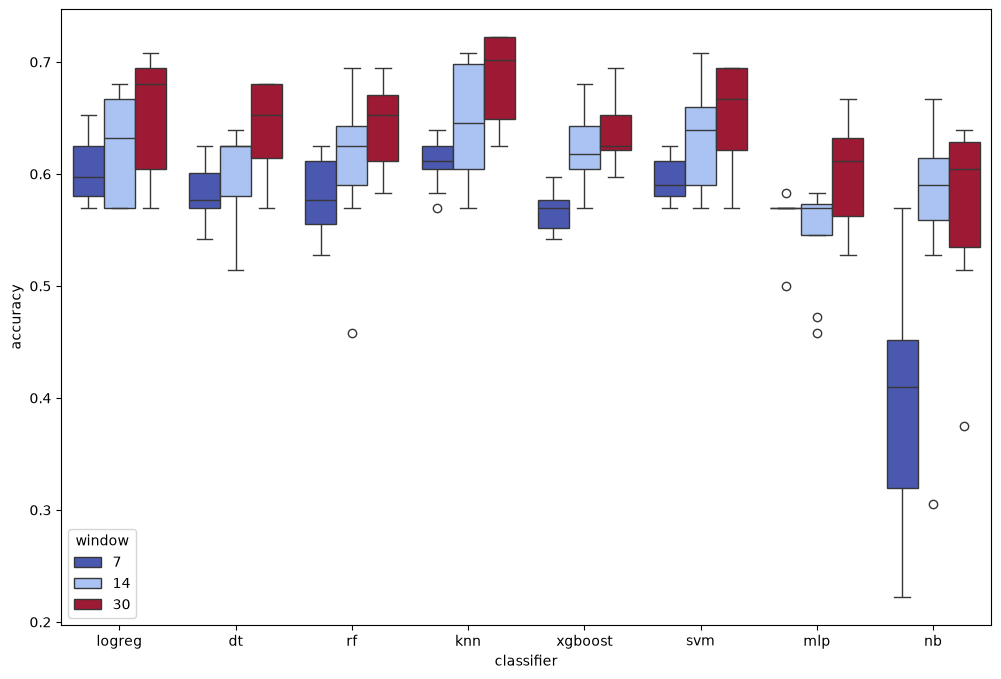

In [18]:
# 
plt.figure(figsize=(12, 8))
sns.boxplot(
    data=df[df['feature'] == 'event_type'],
    x='classifier',
    y='accuracy',
    hue='window',
    palette='coolwarm'
)

<Axes: xlabel='classifier', ylabel='accuracy'>

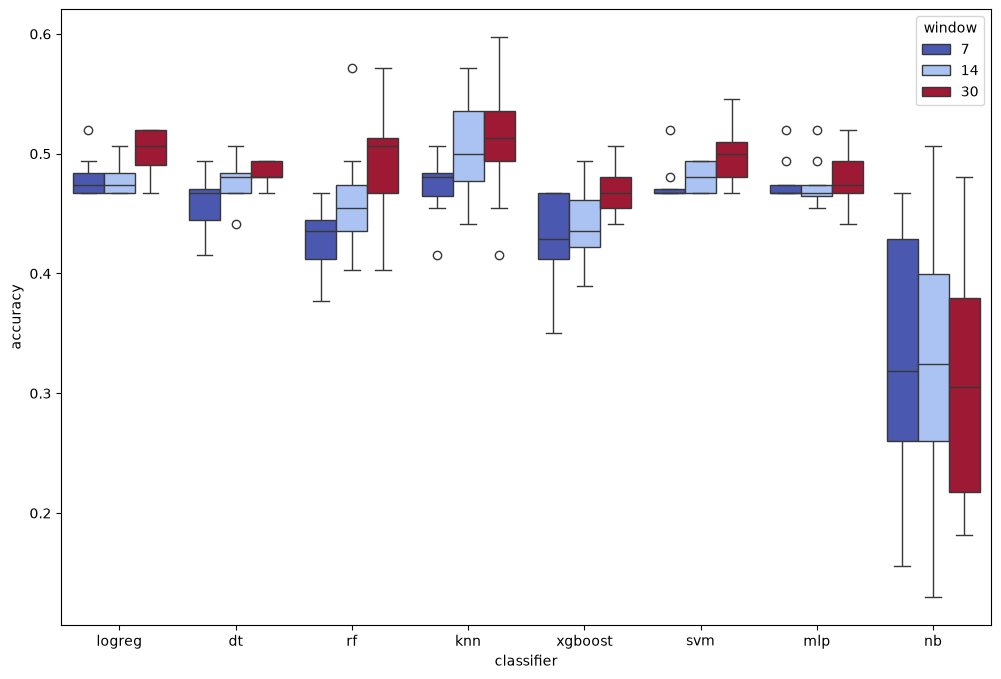

In [19]:
plt.figure(figsize=(12, 8))
sns.boxplot(
    data=df[df['feature'] == 'Continent'],
    x='classifier',
    y='accuracy',
    hue='window',
    palette='coolwarm'
)

/tmp/ipykernel_1573920/1918095095.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


<Axes: xlabel='classifier', ylabel='accuracy'>

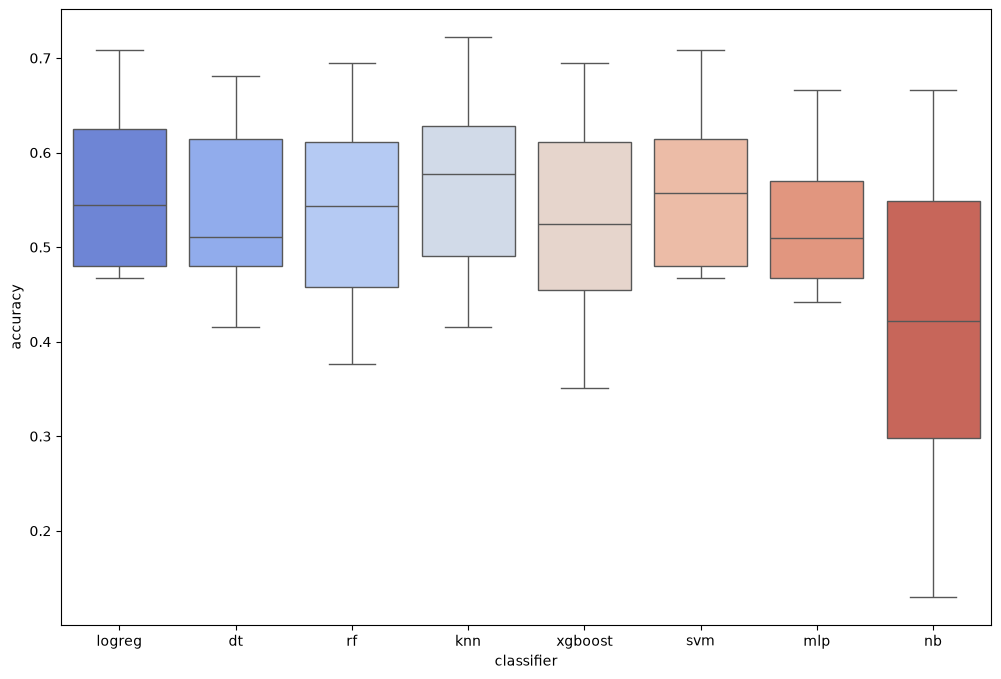

In [21]:
plt.figure(figsize=(12, 8))
sns.boxplot(
    data=df,
    x='classifier',
    y='accuracy',
    #hue='window',
    palette='coolwarm'
)